# Reinforcement-learning qubit routing in PyTorch

**Sharon Xalxo** · [github.com/SharonXal](https://github.com/SharonXal)

This notebook builds a small reinforcement-learning transpiler pass from scratch. A **PPO agent** written in PyTorch learns to insert SWAP gates so that a quantum circuit can run on hardware with restricted qubit connectivity. It is benchmarked against a hand-written heuristic and Qiskit's **SABRE** router, and **every routed circuit is checked for functional equivalence** with the original.

**Contents**
1. Setup
2. Hardware coupling graphs
3. Circuits to route
4. The routing MDP
5. Verifying a routed circuit
6. Baselines: greedy heuristic and Qiskit SABRE
7. The policy network
8. PPO training
9. Evaluation on seen and unseen topologies
10. What this shows, and next steps

The whole notebook runs on a laptop CPU. Training takes about 3 minutes and evaluation a few more.

## 1. Setup

In [ ]:
# %pip install torch qiskit networkx numpy matplotlib pandas

import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from qiskit import QuantumCircuit
from qiskit.transpiler import CouplingMap, Layout, PassManager
from qiskit.transpiler.passes import ApplyLayout, FullAncillaAllocation, SabreSwap, SetLayout

torch.set_num_threads(2)
torch.manual_seed(0)
print("torch", torch.__version__)

torch 2.14.1+cu130


## 2. Hardware coupling graphs

Each node is a physical qubit; an edge means a two-qubit gate is allowed between those qubits. The agent trains on three small graphs. Evaluation adds four topologies it **never sees during training**, including a fragment with the degree pattern of IBM's heavy-hex lattice.

In [2]:
def line(n):
    return nx.path_graph(n)


def ring(n):
    return nx.cycle_graph(n)


def grid(r, c):
    g = nx.grid_2d_graph(r, c)
    return nx.convert_node_labels_to_integers(g, ordering="sorted")


def heavy_hex_fragment():
    """A 10-qubit fragment with the degree-2/degree-3 pattern of IBM heavy-hex
    lattices: two hexagon-like loops sharing a bridge, sparse connectivity."""
    edges = [(0, 1), (1, 2), (2, 3), (3, 4),        # top row
             (0, 5), (4, 6),                        # bridge qubits
             (5, 7), (7, 8), (8, 9), (9, 6),        # bottom row
             (2, 8)]                                # central bridge
    g = nx.Graph()
    g.add_edges_from(edges)
    return g


def tree7():
    """Binary tree: a hierarchical topology with long detours between leaves."""
    return nx.balanced_tree(2, 2)


TRAIN_GRAPHS = {
    "line6": line(6),
    "ring6": ring(6),
    "grid2x3": grid(2, 3),
}

TEST_GRAPHS = {
    # seen during training
    "line6": line(6),
    "grid2x3": grid(2, 3),
    # never seen during training (different size and topology)
    "ring8": ring(8),
    "grid3x3": grid(3, 3),
    "heavyhex10": heavy_hex_fragment(),
    "tree7": tree7(),
}

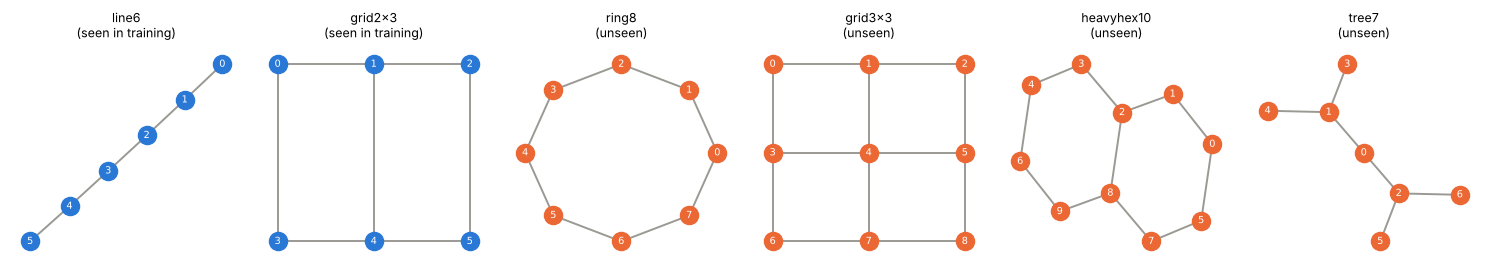

In [3]:
fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
for ax, (name, g) in zip(axes, TEST_GRAPHS.items()):
    if name.startswith("grid"):   # draw grids on their lattice: node i = row*cols + col
        cols = int(name[-1])
        pos = {i: (i % cols, -(i // cols)) for i in g.nodes}
    else:
        pos = nx.kamada_kawai_layout(g)
    seen = name in TRAIN_GRAPHS
    nx.draw(g, pos, ax=ax, node_size=170, width=1.4, node_color="#2a78d6" if seen else "#eb6834",
            edge_color="#9a9993", with_labels=True, font_size=7, font_color="white")
    ax.set_title(f"{name}\n({'seen in training' if seen else 'unseen'})", fontsize=9)
plt.tight_layout()
plt.show()

## 3. Circuits to route

A circuit is a list of two-qubit gates `(a, b, U)` on logical qubits. Each `U` is a **Haar-random SU(4)** unitary. Random SU(4) gates are not symmetric under qubit exchange and do not commute, so the correctness check in Section 5 catches any routing mistake: wrong pairing, wrong order or wrong orientation.

Two workloads are used: random circuits, and the all-to-all interaction pattern of the QFT, which is dense and stresses sparse topologies.

In [4]:
def haar_unitary(d, rng):
    z = (rng.standard_normal((d, d)) + 1j * rng.standard_normal((d, d))) / np.sqrt(2)
    q, r = np.linalg.qr(z)
    ph = np.diag(r) / np.abs(np.diag(r))
    return q * ph


def random_circuit(n_qubits, n_gates, rng, with_unitaries=True):
    gates = []
    for _ in range(n_gates):
        a, b = rng.choice(n_qubits, size=2, replace=False)
        U = haar_unitary(4, rng) if with_unitaries else None
        gates.append((int(a), int(b), U))
    return gates


def qft_pattern(n_qubits, rng, with_unitaries=True):
    """All-to-all interaction pattern of the QFT: gate (i, j) for every i < j,
    in QFT order. Structured and dense, so it stresses sparse topologies."""
    gates = []
    for i in range(n_qubits):
        for j in range(i + 1, n_qubits):
            U = haar_unitary(4, rng) if with_unitaries else None
            gates.append((i, j, U))
    return gates

## 4. The routing MDP

Hardware only lets adjacent qubits interact, so the router inserts SWAPs to move logical qubits around. Each SWAP costs 3 CNOTs, so **fewer SWAPs means less depth and less error**.

| | |
|---|---|
| **State** | current logical-to-physical mapping and the remaining gates (front layer plus a 20-gate lookahead window) |
| **Action** | choose one hardware edge and apply a SWAP on it |
| **Dynamics** | any front-layer gate whose qubits become adjacent is executed automatically |
| **Reward** | −1 per SWAP, plus potential-based shaping from upcoming gate distances |

**Reward shaping.** The shaping term is $F = \Phi(s') - \Phi(s)$, where $\Phi(s)$ is minus the summed excess distance of upcoming gates. It telescopes over an episode, so it speeds up learning without changing which policy is optimal (Ng, Harada and Russell, 1999).

**Per-edge observation.** Each candidate SWAP gets a 6-dimensional feature vector:
1. change in mean front-layer distance;
2. change in mean lookahead distance;
3. fraction of front-layer gates it makes executable;
4. whether it touches qubits in the front layer;
5. whether it undoes the previous SWAP;
6. the endpoints' degree.

Because the policy scores each edge separately, the network does not depend on the size of the graph.

In [5]:
N_EDGE_FEATS = 6
N_GLOBAL_FEATS = 5


class RoutingEnv:
    def __init__(self, graph, gates, lookahead=20, w_look=0.5,
                 shaping=0.5, max_swaps=None):
        self.graph = graph
        self.n = graph.number_of_nodes()
        self.gates = [(a, b) for a, b, _ in gates]
        self.G = len(self.gates)
        self.edges = sorted(tuple(sorted(e)) for e in graph.edges())
        self.E = len(self.edges)
        D = dict(nx.all_pairs_shortest_path_length(graph))
        self.D = np.array([[D[i][j] for j in range(self.n)] for i in range(self.n)],
                          dtype=np.float32)
        self.diam = float(self.D.max())
        self.lookahead = lookahead
        self.w_look = w_look
        self.shaping = shaping
        self.max_swaps = max_swaps or max(20, 4 * self.G * int(self.diam))

    # ------------------------------------------------------------------ core
    def reset(self):
        self.l2p = np.arange(self.n)
        self.p2l = np.arange(self.n)
        self.pending = list(range(self.G))
        self.ops = []            # routed program: ("gate", i, p, q) / ("swap", p, q)
        self.n_swaps = 0
        self.last_swap = None
        self._execute_ready()
        return self._obs()

    def _layers(self):
        """Front layer = pending gates with no earlier pending gate on their
        qubits. Lookahead = the next few pending gates after the front."""
        blocked, front, look = set(), [], []
        for i in self.pending:
            a, b = self.gates[i]
            if a not in blocked and b not in blocked:
                front.append(i)
            elif len(look) < self.lookahead:
                look.append(i)
            blocked.add(a)
            blocked.add(b)
        return front, look

    def _dist(self, i, l2p):
        a, b = self.gates[i]
        return self.D[l2p[a], l2p[b]]

    def _execute_ready(self):
        while True:
            front, _ = self._layers()
            ready = [i for i in front if self._dist(i, self.l2p) == 1]
            if not ready:
                return
            for i in ready:
                a, b = self.gates[i]
                self.ops.append(("gate", i, int(self.l2p[a]), int(self.l2p[b])))
                self.pending.remove(i)

    def _potential(self):
        front, look = self._layers()
        s = sum(self._dist(i, self.l2p) - 1 for i in front)
        s += self.w_look * sum(self._dist(i, self.l2p) - 1 for i in look)
        return -float(s)

    def step(self, edge_idx):
        phi0 = self._potential()
        p, q = self.edges[edge_idx]
        lp, lq = self.p2l[p], self.p2l[q]
        self.p2l[p], self.p2l[q] = lq, lp
        self.l2p[lp], self.l2p[lq] = q, p
        self.ops.append(("swap", p, q))
        self.n_swaps += 1
        self.last_swap = edge_idx
        self._execute_ready()
        done = len(self.pending) == 0
        phi1 = 0.0 if done else self._potential()
        reward = -1.0 + self.shaping * (phi1 - phi0)
        truncated = (not done) and self.n_swaps >= self.max_swaps
        return self._obs(), reward, done, truncated

    # ----------------------------------------------------------- observation
    def edge_scores(self):
        """Raw per-edge quantities shared by the RL features and the greedy
        baseline: (delta_front, delta_look, n_newly_executable)."""
        front, look = self._layers()
        base_f = np.array([self._dist(i, self.l2p) for i in front])
        base_l = np.array([self._dist(i, self.l2p) for i in look])
        out = []
        for (p, q) in self.edges:
            l2p = self.l2p.copy()
            lp, lq = self.p2l[p], self.p2l[q]
            l2p[lp], l2p[lq] = q, p
            nf = np.array([self._dist(i, l2p) for i in front])
            nl = np.array([self._dist(i, l2p) for i in look])
            df = (nf.sum() - base_f.sum()) / max(len(front), 1)
            dl = (nl.sum() - base_l.sum()) / max(len(look), 1) if look else 0.0
            newly = int((nf == 1).sum())
            out.append((df, dl, newly))
        return out, front, look

    def _obs(self):
        if not self.pending:
            return None
        scores, front, look = self.edge_scores()
        front_qubits = {self.l2p[q] for i in front for q in self.gates[i]}
        feats = np.zeros((self.E, N_EDGE_FEATS), dtype=np.float32)
        for k, ((p, q), (df, dl, newly)) in enumerate(zip(self.edges, scores)):
            feats[k] = [df, dl, newly / max(len(front), 1),
                        float(p in front_qubits) + float(q in front_qubits),
                        float(k == self.last_swap),
                        (self.graph.degree[p] + self.graph.degree[q]) / 6.0]
        hf = np.mean([self._dist(i, self.l2p) for i in front]) / self.diam
        hl = (np.mean([self._dist(i, self.l2p) for i in look]) / self.diam) if look else 0.0
        glob = np.array([len(self.pending) / self.G, len(front) / self.n, hf, hl,
                         self.n_swaps / max(self.G, 1)], dtype=np.float32)
        mask = np.ones(self.E, dtype=bool)
        if self.last_swap is not None:
            mask[self.last_swap] = False   # never undo the previous SWAP
        return {"edge": feats, "glob": glob, "mask": mask}

## 5. Verifying a routed circuit

Two checks are applied to every routed program:
1. **Hardware legality:** every gate and SWAP acts on a real edge.
2. **Functional equivalence:** random input states are evolved through the logical circuit and through the routed physical circuit. After undoing the final qubit permutation, the two states must agree to numerical precision.

In [6]:
def _apply(state, U, a, b):
    Ut = U.reshape(2, 2, 2, 2)
    out = np.tensordot(Ut, state, axes=([2, 3], [a, b]))
    return np.moveaxis(out, [0, 1], [a, b])


def verify(env, gates, n_states=3, seed=0):
    rng = np.random.default_rng(seed)
    n = env.n
    edges = set(env.edges)
    for op in env.ops:
        p, q = op[-2], op[-1]
        if tuple(sorted((p, q))) not in edges:
            return False, 0.0
    worst = 1.0
    for _ in range(n_states):
        psi = rng.standard_normal(2 ** n) + 1j * rng.standard_normal(2 ** n)
        psi = (psi / np.linalg.norm(psi)).reshape((2,) * n)
        logical = psi.copy()
        for a, b, U in gates:
            logical = _apply(logical, U, a, b)
        phys = psi.copy()
        for op in env.ops:
            if op[0] == "swap":
                phys = np.swapaxes(phys, op[1], op[2])
            else:
                _, i, pa, pb = op
                phys = _apply(phys, gates[i][2], pa, pb)
        phys = np.transpose(phys, env.l2p)   # logical axis j <- physical axis l2p[j]
        fid = abs(np.vdot(logical.ravel(), phys.ravel())) ** 2
        worst = min(worst, fid)
    return worst > 1 - 1e-9, worst

## 6. Baselines

* **Greedy heuristic:** at each step, pick the SWAP that most reduces front-layer distance plus 0.5 × lookahead distance. It sees the same information as the RL agent and does no learning.
* **Qiskit SABRE** (Li, Ding and Xie, ASPLOS 2019): the industry-default router, run with 5 randomised trials. All routers use the same fixed trivial initial layout, so only routing quality is compared.

In [7]:
def greedy_route(graph, gates, w_look=0.5):
    env = RoutingEnv(graph, gates, w_look=w_look)
    obs = env.reset()
    done = obs is None
    truncated = False
    while not (done or truncated):
        scores, _, _ = env.edge_scores()
        cost = np.array([df + w_look * dl for df, dl, _ in scores])
        cost[~obs["mask"]] = np.inf
        obs, _, done, truncated = env.step(int(np.argmin(cost)))
    return env, done


def sabre_swaps(graph, gates, seed=0, trials=5):
    n = graph.number_of_nodes()
    qc = QuantumCircuit(n)
    for a, b, _ in gates:
        qc.cx(a, b)
    cmap = CouplingMap([list(e) for e in graph.edges()])
    cmap.make_symmetric()
    layout = Layout({qc.qubits[i]: i for i in range(n)})
    pm = PassManager([SetLayout(layout), FullAncillaAllocation(cmap), ApplyLayout(),
                      SabreSwap(cmap, heuristic="decay", seed=seed, trials=trials)])
    out = pm.run(qc)
    return out.count_ops().get("swap", 0)

**Putting Sections 4–6 together.** Route one random circuit on the heavy-hex fragment with the greedy heuristic, verify it, then corrupt it on purpose to show that the check catches the error.

In [8]:
rng_demo = np.random.default_rng(7)
g = TEST_GRAPHS["heavyhex10"]
gates = random_circuit(g.number_of_nodes(), 20, rng_demo)
env, done = greedy_route(g, gates)
print(f"routed: {done},  SWAPs inserted: {env.n_swaps}")
print("first 10 routed operations:", env.ops[:10])

ok, fid = verify(env, gates)
print(f"verified: {ok}, worst state fidelity = {fid:.12f}")

# negative control: delete one SWAP and the check must fail
i = next(k for k, op in enumerate(env.ops) if op[0] == "swap")
env.ops.pop(i)
print("after deleting one SWAP ->", verify(env, gates))

routed: True,  SWAPs inserted: 16
first 10 routed operations: [('swap', 5, 7), ('swap', 6, 9), ('gate', 0, 8, 9), ('swap', 8, 9), ('gate', 1, 6, 9), ('gate', 6, 7, 8), ('swap', 3, 4), ('gate', 2, 4, 6), ('gate', 10, 6, 4), ('swap', 8, 9)]
verified: True, worst state fidelity = 1.000000000000
after deleting one SWAP -> (np.False_, np.float64(0.23988236946847474))


## 7. The policy network

An **edge-scoring actor-critic**:
* **Actor:** a shared MLP maps each edge's features, concatenated with global features, to a logit. A masked softmax over the edges gives the SWAP distribution. Undoing the previous SWAP is masked out.
* **Critic:** mean- and max-pooled edge embeddings plus the global features give $V(s)$.

Different graphs have different numbers of edges, so batches are padded and masked.

In [9]:
class EdgeActorCritic(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        inp = N_EDGE_FEATS + N_GLOBAL_FEATS
        self.embed = nn.Sequential(nn.Linear(inp, hidden), nn.Tanh(),
                                   nn.Linear(hidden, hidden), nn.Tanh())
        self.actor_head = nn.Linear(hidden, 1)
        self.critic = nn.Sequential(nn.Linear(2 * hidden + N_GLOBAL_FEATS, hidden),
                                    nn.Tanh(), nn.Linear(hidden, 1))

    def forward(self, edge, glob, mask):
        """edge: (B, E, F)  glob: (B, Fg)  mask: (B, E) bool (True = allowed,
        False = forbidden or padding)."""
        B, E, _ = edge.shape
        x = torch.cat([edge, glob.unsqueeze(1).expand(B, E, -1)], dim=-1)
        h = self.embed(x)
        logits = self.actor_head(h).squeeze(-1)
        logits = logits.masked_fill(~mask, -1e9)
        m = mask.unsqueeze(-1).float()
        mean = (h * m).sum(1) / m.sum(1).clamp(min=1)
        mx = h.masked_fill(~mask.unsqueeze(-1), -1e9).max(1).values
        value = self.critic(torch.cat([mean, mx, glob], dim=-1)).squeeze(-1)
        return logits, value

    @torch.no_grad()
    def act(self, obs, greedy=False):
        edge = torch.as_tensor(obs["edge"]).unsqueeze(0)
        glob = torch.as_tensor(obs["glob"]).unsqueeze(0)
        mask = torch.as_tensor(obs["mask"]).unsqueeze(0)
        logits, value = self(edge, glob, mask)
        dist = torch.distributions.Categorical(logits=logits)
        a = logits.argmax(-1) if greedy else dist.sample()
        return int(a), float(dist.log_prob(a)), float(value)


def collate(obs_list):
    """Pad a list of per-step observations (different graphs have different
    edge counts) into batched tensors."""
    Emax = max(o["edge"].shape[0] for o in obs_list)
    B = len(obs_list)
    edge = np.zeros((B, Emax, N_EDGE_FEATS), dtype=np.float32)
    mask = np.zeros((B, Emax), dtype=bool)
    glob = np.stack([o["glob"] for o in obs_list])
    for i, o in enumerate(obs_list):
        e = o["edge"].shape[0]
        edge[i, :e] = o["edge"]
        mask[i, :e] = o["mask"]
    return torch.as_tensor(edge), torch.as_tensor(glob), torch.as_tensor(mask)

## 8. PPO training

Proximal Policy Optimisation (Schulman et al., 2017) with generalised advantage estimation (GAE, $\lambda = 0.95$), clip 0.2 and an entropy bonus.

The training distribution draws one of the three training graphs, then a random circuit of 10–30 gates (80% of the time) or the QFT pattern (20%). Every 5 updates, the greedy (argmax) policy is scored on a fixed validation set of 30 held-out circuits, and the best checkpoint is kept.

In [10]:
CFG = dict(updates=400, episodes=24, lr=3e-4, gamma=0.99, lam=0.95, clip=0.2,
           epochs=4, minibatch=256, ent=0.01, reward_scale=0.1, seed=0)

rng = np.random.default_rng(CFG["seed"])
torch.manual_seed(CFG["seed"])
graph_names = list(TRAIN_GRAPHS)


def sample_task(rng):
    g = TRAIN_GRAPHS[graph_names[rng.integers(len(graph_names))]]
    n = g.number_of_nodes()
    if rng.random() < 0.2:
        return g, qft_pattern(n, rng, with_unitaries=False)
    return g, random_circuit(n, int(rng.integers(10, 31)), rng, with_unitaries=False)


val_rng = np.random.default_rng(12345)
VAL = [(g, random_circuit(g.number_of_nodes(), 20, val_rng, with_unitaries=False))
       for g in TRAIN_GRAPHS.values() for _ in range(10)]
VAL_GREEDY = np.mean([greedy_route(g, c)[0].n_swaps for g, c in VAL])


def run_policy(model, g, gates, greedy=True):
    env = RoutingEnv(g, gates)
    obs = env.reset()
    done, trunc = obs is None, False
    while not (done or trunc):
        a, _, _ = model.act(obs, greedy=greedy)
        obs, _, done, trunc = env.step(a)
    return env, done


def validate(model):
    envs = [run_policy(model, g, c)[0] for g, c in VAL]
    return np.mean([e.n_swaps for e in envs]), sum(e.n_swaps >= e.max_swaps for e in envs)

In [11]:
model = EdgeActorCritic()
opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
history, best, best_state, t0 = [], float("inf"), None, time.time()

for upd in range(1, CFG["updates"] + 1):
    obs_buf, act_buf, logp_buf, adv_buf, ret_buf, ep_swaps = [], [], [], [], [], []
    # ---- collect a batch of episodes with the current stochastic policy
    for _ in range(CFG["episodes"]):
        g, c = sample_task(rng)
        env = RoutingEnv(g, c)
        obs = env.reset()
        if obs is None:
            continue
        o_l, a_l, lp_l, v_l, r_l = [], [], [], [], []
        done = trunc = False
        while not (done or trunc):
            a, lp, v = model.act(obs)
            nobs, r, done, trunc = env.step(a)
            o_l.append(obs); a_l.append(a); lp_l.append(lp); v_l.append(v)
            r_l.append(r * CFG["reward_scale"])
            obs = nobs
        # ---- generalised advantage estimation
        adv, last = np.zeros(len(r_l), dtype=np.float32), 0.0
        for t in reversed(range(len(r_l))):
            nv = v_l[t + 1] if t + 1 < len(r_l) else 0.0
            delta = r_l[t] + CFG["gamma"] * nv - v_l[t]
            last = delta + CFG["gamma"] * CFG["lam"] * last
            adv[t] = last
        obs_buf += o_l; act_buf += a_l; logp_buf += lp_l
        adv_buf += list(adv); ret_buf += list(adv + np.array(v_l, dtype=np.float32))
        ep_swaps.append(env.n_swaps)

    # ---- PPO update
    edge, glob, mask = collate(obs_buf)
    acts = torch.as_tensor(act_buf)
    old_lp = torch.as_tensor(logp_buf, dtype=torch.float32)
    adv = torch.as_tensor(np.array(adv_buf), dtype=torch.float32)
    adv = (adv - adv.mean()) / (adv.std() + 1e-8)
    ret = torch.as_tensor(np.array(ret_buf), dtype=torch.float32)
    N = len(acts)
    for _ in range(CFG["epochs"]):
        perm = torch.randperm(N)
        for s in range(0, N, CFG["minibatch"]):
            idx = perm[s:s + CFG["minibatch"]]
            logits, value = model(edge[idx], glob[idx], mask[idx])
            dist = torch.distributions.Categorical(logits=logits)
            ratio = torch.exp(dist.log_prob(acts[idx]) - old_lp[idx])
            pg = -torch.min(ratio * adv[idx],
                            torch.clamp(ratio, 1 - CFG["clip"], 1 + CFG["clip"]) * adv[idx]).mean()
            loss = pg + 0.5 * ((value - ret[idx]) ** 2).mean() - CFG["ent"] * dist.entropy().mean()
            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 0.5)
            opt.step()

    # ---- validation
    if upd == 1 or upd % 5 == 0:
        val, fails = validate(model)
        history.append((upd * CFG["episodes"], val))
        if fails == 0 and val < best:
            best, best_state = val, {k: v.clone() for k, v in model.state_dict().items()}
        if upd == 1 or upd % 50 == 0:
            print(f"update {upd:4d} | train swaps {np.mean(ep_swaps):6.2f} | "
                  f"val {val:6.2f} (greedy {VAL_GREEDY:.2f}) | {time.time() - t0:5.0f}s")

model.load_state_dict(best_state)
model.eval()
print(f"\nbest validation mean SWAPs {best:.2f}  vs greedy {VAL_GREEDY:.2f}")

update    1 | train swaps  49.54 | val  30.60 (greedy 12.70) |     2s


update   50 | train swaps  12.88 | val  12.77 (greedy 12.70) |    28s


update  100 | train swaps  12.12 | val  12.47 (greedy 12.70) |    48s


update  150 | train swaps  12.42 | val  12.60 (greedy 12.70) |    68s


update  200 | train swaps  12.33 | val  12.50 (greedy 12.70) |    88s


update  250 | train swaps  12.17 | val  12.57 (greedy 12.70) |   107s


update  300 | train swaps  12.96 | val  12.57 (greedy 12.70) |   126s


update  350 | train swaps  13.12 | val  12.83 (greedy 12.70) |   145s


update  400 | train swaps  12.92 | val  12.60 (greedy 12.70) |   164s

best validation mean SWAPs 12.33  vs greedy 12.70


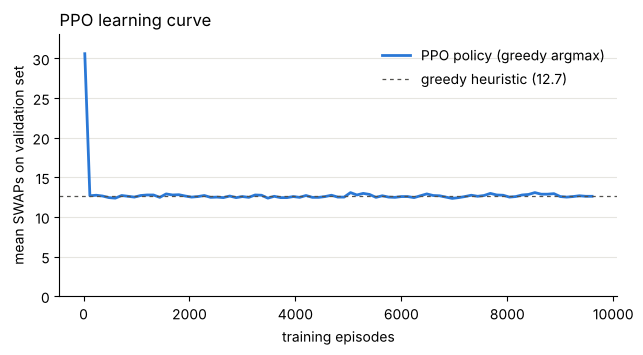

In [12]:
ep, val = zip(*history)
fig, ax = plt.subplots(figsize=(7.2, 3.4))
ax.plot(ep, val, color="#2a78d6", lw=2, label="PPO policy (greedy argmax)")
ax.axhline(VAL_GREEDY, color="#52514e", lw=0.9, ls=(0, (3, 3)), label=f"greedy heuristic ({VAL_GREEDY:.1f})")
ax.set_ylim(0, max(val) * 1.08)
ax.set_xlabel("training episodes"); ax.set_ylabel("mean SWAPs on validation set")
ax.set_title("PPO learning curve", loc="left")
ax.grid(axis="y", color="#e6e5e0"); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

The policy reaches the greedy heuristic's level within roughly a hundred episodes and then plateaus. Section 10 discusses why.

## 9. Evaluation on seen and unseen topologies

For each of the six test graphs, three workloads are routed: 20 random 20-gate circuits, 20 random 40-gate circuits, and the QFT pattern. Four routers are compared:

* **RL, 1 pass:** the deterministic argmax policy.
* **RL, best of 6:** the deterministic pass plus 5 sampled rollouts, keeping the cheapest. This matches SABRE's 5 randomised trials.
* **Greedy heuristic.**
* **Qiskit SABRE** (5 trials).

Every RL output is verified.

In [13]:
def rl_best_of_k(g, gates, k=5):
    cands = [run_policy(model, g, gates, greedy=True)]
    cands += [run_policy(model, g, gates, greedy=False) for _ in range(k)]
    cands = [c for c in cands if c[1]] or cands
    return min(cands, key=lambda c: c[0].n_swaps)


rng_eval = np.random.default_rng(2026)
torch.manual_seed(2026)          # makes the sampled rollouts reproducible
rows, t0 = [], time.time()
for gname, g in TEST_GRAPHS.items():
    n = g.number_of_nodes()
    workloads = [("rand20", random_circuit(n, 20, rng_eval)) for _ in range(20)]
    workloads += [("rand40", random_circuit(n, 40, rng_eval)) for _ in range(20)]
    workloads += [("qft", qft_pattern(n, rng_eval))]
    for wname, gates in workloads:
        e1, d1 = run_policy(model, g, gates)
        ek, dk = rl_best_of_k(g, gates)
        eg, _ = greedy_route(g, gates)
        ok1, f1 = verify(e1, gates) if d1 else (False, 0.0)
        okk, fk = verify(ek, gates) if dk else (False, 0.0)
        rows.append(dict(graph=gname, seen=gname in TRAIN_GRAPHS, workload=wname,
                         rl_1pass=e1.n_swaps, rl_best6=ek.n_swaps, greedy=eg.n_swaps,
                         sabre=sabre_swaps(g, gates), verified=ok1 and okk, fidelity=min(f1, fk)))
df = pd.DataFrame(rows)
print(f"{len(df)} circuits routed in {time.time() - t0:.0f}s")
print(f"RL outputs verified: {df.verified.sum()}/{len(df)},  worst fidelity {df.fidelity.min():.12f}")

246 circuits routed in 46s
RL outputs verified: 246/246,  worst fidelity 1.000000000000


In [14]:
table = (df.groupby(["graph", "seen", "workload"], sort=False)
           [["rl_1pass", "rl_best6", "greedy", "sabre"]].mean().round(1))
sums = df.groupby(["graph", "seen", "workload"], sort=False)[["rl_best6", "sabre"]].sum()
table["rl_best6 / sabre"] = (sums.rl_best6 / sums.sabre).round(2)
table

rl_1pass  rl_best6  greedy  sabre  rl_best6 / sabre
graph      seen  workload                                                     
line6      True  rand20        18.0      16.8    18.2   16.2              1.03
                 rand40        35.4      33.0    36.0   30.6              1.08
                 qft           12.0      12.0    12.0   13.0              0.92
grid2x3    True  rand20         8.5       7.4     8.6    7.6              0.98
                 rand40        18.1      15.6    17.8   14.1              1.11
                 qft            7.0       7.0     7.0    7.0              1.00
ring8      False rand20        18.6      17.0    18.2   16.4              1.04
                 rand40        37.4      34.0    38.7   33.0              1.03
                 qft           25.0      25.0    25.0   26.0              0.96
grid3x3    False rand20        11.9       9.6    11.2   10.0              0.95
                 rand40        25.6      21.0    22.7   20.7              1.01
                 qft           21.0      21.0    20.0   22.0              0.95
heavyhex10 False rand20        19.5      17.6    18.8   17.2              1.02
                 rand40        35.4      33.3    37.1   33.0              1.01
                 qft           46.0      45.0    47.0   41.0              1.10
tree7      False rand20        17.6      15.4    17.3   15.0              1.03
                 rand40        34.4      30.9    34.1   28.4              1.09
                 qft           14.0      13.0    24.0   13.0              1.00

In [15]:
def totals(d):
    return {k: int(d[k].sum()) for k in ["rl_1pass", "rl_best6", "greedy", "sabre"]}

summary = pd.DataFrame({"all graphs": totals(df), "unseen graphs only": totals(df[~df.seen])}).T
for k in ["rl_1pass", "rl_best6", "greedy"]:
    summary[f"{k} / sabre"] = (summary[k] / summary["sabre"]).round(3)
summary

,rl_1pass,rl_best6,greedy,sabre,rl_1pass / sabre,rl_best6 / sabre,greedy / sabre
all graphs,5732,5156,5709,4967,1.154,1.038,1.149
unseen graphs only,4114,3681,4078,3576,1.150,1.029,1.140


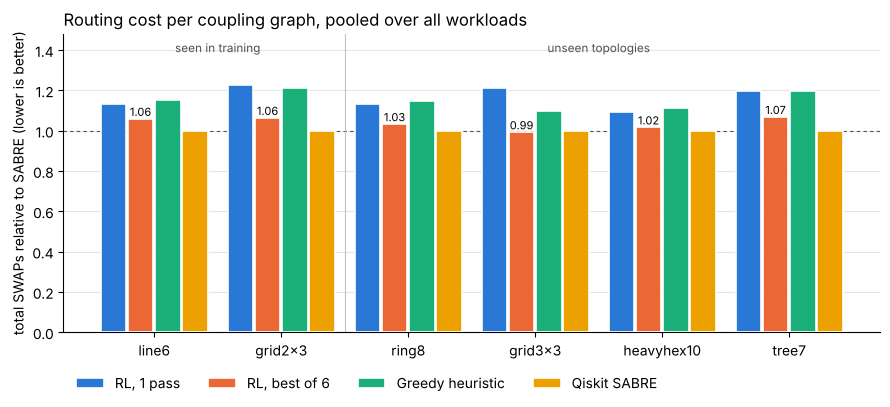

In [16]:
COL = {"RL, 1 pass": "#2a78d6", "RL, best of 6": "#eb6834",
       "Greedy heuristic": "#1baf7a", "Qiskit SABRE": "#eda100"}
KEY = {"RL, 1 pass": "rl_1pass", "RL, best of 6": "rl_best6",
       "Greedy heuristic": "greedy", "Qiskit SABRE": "sabre"}
graphs = list(TEST_GRAPHS)
per_graph = df.groupby("graph", sort=False)[list(KEY.values())].sum().loc[graphs]

fig, ax = plt.subplots(figsize=(9, 4.2))
x, w = np.arange(len(graphs)), 0.2
for k, (name, key) in enumerate(KEY.items()):
    vals = per_graph[key] / per_graph["sabre"]
    bars = ax.bar(x + (k - 1.5) * (w + 0.015), vals, w, color=COL[name], label=name,
                  edgecolor="white", linewidth=1.2, zorder=3)
    if key == "rl_best6":
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=8)
ax.axhline(1.0, color="#52514e", lw=0.8, ls=(0, (3, 3)))
ax.axvline(1.5, color="#c3c2b7", lw=0.8)
ax.text(0.5, 1.39, "seen in training", ha="center", fontsize=8.5, color="#52514e")
ax.text(3.5, 1.39, "unseen topologies", ha="center", fontsize=8.5, color="#52514e")
ax.set_xticks(x, graphs); ax.set_ylim(0, 1.48)
ax.set_ylabel("total SWAPs relative to SABRE (lower is better)")
ax.set_title("Routing cost per coupling graph, pooled over all workloads", loc="left")
ax.grid(axis="y", color="#e6e5e0", zorder=0); ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncol=4, loc="upper left", bbox_to_anchor=(0, -0.1))
plt.tight_layout()
plt.show()

## 10. What this shows, and next steps

**What works**
* The full pipeline runs end to end: MDP formulation, PyTorch policy, PPO training, fair baselines and verification.
* Every RL-routed circuit is legal on the hardware and functionally equivalent to the input circuit.
* One policy trained on three 6-qubit graphs routes correctly on four larger, unseen topologies.
* With compute matched to SABRE's randomised trials (best of 6 rollouts), the learned router comes within a few percent of SABRE, and beats it on some workloads.

**The limitation**
* A single deterministic pass only matches the greedy heuristic. The learning curve reaches that level within a hundred episodes and then plateaus.
* The likely reason is that the hand-designed edge features already encode the greedy decision, so the policy learns to imitate it. Surpassing it requires a richer state representation.

**Next steps**
1. **Graph neural network state:** message passing over the coupling graph and the gate DAG instead of hand-designed features, so the policy can learn strategies a one-step heuristic cannot express.
2. **Joint layout and routing:** learn the initial placement too; here it is fixed to trivial.
3. **Fidelity-weighted reward:** replace the SWAP count with calibrated per-edge error rates from device noise models, so the agent prefers good couplers rather than simply fewer SWAPs.
4. **Native-gate and qudit targets:** extend the action space from SWAPs to native entangling gates on a hardware transition graph, for example trapped-ion qudit level graphs.

**References**
* J. Schulman et al., *Proximal Policy Optimization Algorithms*, arXiv:1707.06347 (2017).
* G. Li, Y. Ding, Y. Xie, *Tackling the Qubit Mapping Problem for NISQ-Era Quantum Devices*, ASPLOS 2019.
* A. Y. Ng, D. Harada, S. Russell, *Policy invariance under reward transformations*, ICML 1999.